In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# HLT Project — GRPO Training on Countdown (Group 2)
**Model:** Qwen2.5-1.5B-Instruct + LoRA (r=16, α=32, all linear layers)
**Method:** GRPO (DeepSeekMath loss, β = 0), reward = rule-based verifier (1.0 correct + 0.1 format)
**Baseline to beat (1.5B CoT, greedy, test):** 26.4% (2 numbers) · 3.0% (3 numbers) · 0.4% (4 numbers, OOD)

## Plan of this notebook
| Step | What | Why |
|---|---|---|
| 1 | Setup | get the code (branch `main`), libraries, GPU |
| 2 | Smoke test (0.5B, 5 steps) | does the pipeline run end to end? |
| 3 | Timing test (1.5B, 10 steps) | seconds/step + memory → confirm the step budget |
| 4 | Stage 1 (2 numbers, 100 steps) | warm-up: format + stop invented numbers |
| 5 | Check Stage 1 on val | did accuracy go up from the baseline? |
| 6 | Stage 2 (3 numbers, 200 steps) | main training, starting from the Stage 1 LoRA |
| 7 | Check Stage 2 on val | pick the best checkpoint |
| 8 | Final evaluation on test | GRPO vs zero-shot vs CoT |
| 9 | Save & download results | zip everything |

In [12]:
# RUN SWITCHES — Save & Run All executes every cell top to bottom.
# These flags decide which heavy steps actually run in this version.
RUN_SMOKE  = False   # Step 2: done, passed
RUN_TIMING = False   # Step 3: done, 26 s/step, 4.4 GB
RUN_STAGE1 = True    # Step 4: train on 2-number puzzles
RUN_VAL1   = True    # Step 5: check Stage 1 on validation

## Step 1 — Setup
**1a.** Clone the repo and switch to the working branch `main` .
**1b.** Install TRL (GRPOTrainer) and PEFT (LoRA), and print the versions so the run is reproducible.
**1c.** Check the GPU (should be a Tesla T4, 16 GB). We use only GPU 0.
**1d.** Make sure the data exists (generated with seed 42, the same as the baselines).

In [2]:
# 1a. Clone once, then use branch main (it has all our code, including src/train/grpo_train.py).
import os
REPO = "hlt-grpo-countdown"
GITHUB_USER = "hamasli"          # <-- change this

if not os.path.exists(f"/kaggle/working/{REPO}"):
    !git clone https://github.com/{GITHUB_USER}/{REPO}.git /kaggle/working/{REPO}
%cd /kaggle/working/{REPO}
!git checkout main
!git pull
!git branch                              # the * must be on main
!ls src/train                            # expect grpo_train.py

Cloning into '/kaggle/working/hlt-grpo-countdown'...
remote: Enumerating objects: 227, done.
remote: Counting objects: 100% (227/227), done.
remote: Compressing objects: 100% (138/138), done.
remote: Total 227 (delta 127), reused 177 (delta 78), pack-reused 0 (from 0)
Receiving objects: 100% (227/227), 1.72 MiB | 16.63 MiB/s, done.
Resolving deltas: 100% (127/127), done.
/kaggle/working/hlt-grpo-countdown
Already on 'main'
Your branch is up to date with 'origin/main'.
Already up to date.
* main
grpo_train.py  __init__.py


1b, libraries

In [3]:


# 1b. TRL = GRPOTrainer, PEFT = LoRA. torch + transformers are already on Kaggle.
# Kaggle's preinstalled torchao (0.10) is too old for the new PEFT and crashes get_peft_model.
# We don't use torchao (it's for quantization), so we remove it.
!pip uninstall -y -q torchao
!pip install -q trl peft
import torch, transformers, trl, peft
print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| trl", trl.__version__, "| peft", peft.__version__)

torch 2.11.0+cu130 | transformers 5.20.2 | trl 1.18.0 | peft 0.21.2


1c, GPU

In [4]:
# 1c. Kaggle gives 2 x T4; the training script uses only GPU 0 (no accelerate launch needed).
print("GPUs visible:", torch.cuda.device_count())
print("GPU 0:", torch.cuda.get_device_name(0),
      "|", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")

GPUs visible: 2
GPU 0: Tesla T4 | 15.6 GB


1d, data

In [11]:
# 1d. The data is generated deterministically (seed 42) -> identical to the baseline data.
if not os.path.exists("data/train.jsonl"):
    !python -m src.data.generate
!wc -l data/*.jsonl                      # expect: train 10000, val 200, test 1000, test_ood 500

   1000 data/test.jsonl
    500 data/test_ood.jsonl
  10000 data/train.jsonl
    200 data/val.jsonl
  11700 total


## Step 2 — Smoke test (0.5B, 5 steps)
**Goal:** check that the whole pipeline runs end to end, NOT to learn anything.
Pipeline: load data → build prompts (v3 + `<think>` prefill) → generate 4 answers per puzzle
→ verifier rewards → GRPO loss → LoRA update → save checkpoint + final adapter + logs.

**Why 0.5B:** it's 3× smaller, so it loads and runs fast. If something is broken, we find out in ~2 minutes instead of 10.
**Why `--logging_steps 1`:** one log line per step, so we see every step.

**Pass if:**
- no error
- `checkpoints/smoke/` contains `checkpoint-5/`, `final/`, `log_history.json`, `run_info.json`
- the log shows `reward` and `rewards/correctness_reward/mean` values
- the format reward is not always 0 (that would mean the `<think>` prefill fix is broken)

2a, run

In [ ]:
# 2a. 5 training steps with the small model. Each step = 8 puzzles x 4 answers = 32 answers.
# !python -m src.train.grpo_train \
#     --model Qwen/Qwen2.5-0.5B-Instruct \
#     --max_steps 5 --logging_steps 1 --save_steps 5 \
#     --output_dir checkpoints/smoke


if RUN_SMOKE:
    !python -m src.train.grpo_train --model Qwen/Qwen2.5-0.5B-Instruct --max_steps 5 --logging_steps 1 --save_steps 5 --output_dir checkpoints/smoke

cell: 2b, check the outputs

In [15]:
# 2b. Did it save everything, and are the rewards being computed?
import json
!ls checkpoints/smoke
!ls checkpoints/smoke/final              # expect adapter_config.json + adapter_model.safetensors

info = json.load(open("checkpoints/smoke/run_info.json"))
print(f"\n{info['steps_done']} steps | {info['seconds_per_step']} s/step | "
      f"peak memory {info['peak_gpu_memory_gb']} GB")

# One line per step: the main metrics.
KEYS = ["reward", "rewards/correctness_reward/mean", "rewards/format_reward_prefill/mean",
        "frac_reward_zero_std", "completions/mean_length", "completions/clipped_ratio"]
for row in json.load(open("checkpoints/smoke/log_history.json")):
    if "reward" in row:
        print(row["step"], {k.split("/")[-2] if "/" in k else k: round(row[k], 3)
                            for k in KEYS if k in row})

checkpoint-5  completions  final  log_history.json  README.md  run_info.json
adapter_config.json	   README.md		  training_args.bin
adapter_model.safetensors  tokenizer_config.json
chat_template.jinja	   tokenizer.json

5 steps | 25.15 s/step | peak memory 1.69 GB
1 {'reward': 0.006, 'correctness_reward': 0.0, 'format_reward_prefill': 0.006, 'frac_reward_zero_std': 0.75, 'completions': 0.062}
2 {'reward': 0.038, 'correctness_reward': 0.031, 'format_reward_prefill': 0.006, 'frac_reward_zero_std': 0.75, 'completions': 0.062}
3 {'reward': 0.006, 'correctness_reward': 0.0, 'format_reward_prefill': 0.006, 'frac_reward_zero_std': 0.75, 'completions': 0.156}
4 {'reward': 0.016, 'correctness_reward': 0.0, 'format_reward_prefill': 0.016, 'frac_reward_zero_std': 0.375, 'completions': 0.094}
5 {'reward': 0.016, 'correctness_reward': 0.0, 'format_reward_prefill': 0.016, 'frac_reward_zero_std': 0.5, 'completions': 0.0}


In [17]:
# 2b. Did it save everything, and are the rewards being computed?
import json
!ls checkpoints/smoke
!ls checkpoints/smoke/final              # expect adapter_config.json + adapter_model.safetensors

info = json.load(open("checkpoints/smoke/run_info.json"))
print(f"\n{info['steps_done']} steps | {info['seconds_per_step']} s/step | "
      f"peak memory {info['peak_gpu_memory_gb']} GB")

# One line per step. Short names -> full metric keys in TRL's log.
KEYS = {"reward": "reward",
        "correct": "rewards/correctness_reward/mean",
        "format": "rewards/format_reward_prefill/mean",
        "no_signal": "frac_reward_zero_std",
        "length": "completions/mean_length",
        "clipped": "completions/clipped_ratio"}
for row in json.load(open("checkpoints/smoke/log_history.json")):
    if "reward" in row:
        print("step", row["step"], {short: round(row[full], 3) for short, full in KEYS.items() if full in row})

checkpoint-5  completions  final  log_history.json  README.md  run_info.json
adapter_config.json	   README.md		  training_args.bin
adapter_model.safetensors  tokenizer_config.json
chat_template.jinja	   tokenizer.json

5 steps | 25.15 s/step | peak memory 1.69 GB
step 1 {'reward': 0.006, 'correct': 0.0, 'format': 0.006, 'no_signal': 0.75, 'length': 71.469, 'clipped': 0.062}
step 2 {'reward': 0.038, 'correct': 0.031, 'format': 0.006, 'no_signal': 0.75, 'length': 73.594, 'clipped': 0.062}
step 3 {'reward': 0.006, 'correct': 0.0, 'format': 0.006, 'no_signal': 0.75, 'length': 101.656, 'clipped': 0.156}
step 4 {'reward': 0.016, 'correct': 0.0, 'format': 0.016, 'no_signal': 0.375, 'length': 86.656, 'clipped': 0.094}
step 5 {'reward': 0.016, 'correct': 0.0, 'format': 0.016, 'no_signal': 0.5, 'length': 62.875, 'clipped': 0.0}


The per-step numbers (each step = 32 answers)
Value	Meaning	Example
reward	average total reward per answer	step 2: 0.038
correctness_reward	fraction of answers correct	step 2: 0.031 = 1 of 32 correct
format_reward_prefill	0.1 × fraction with correct format	0.006 → ~6% formatted (2 of 32)
frac_reward_zero_std	fraction of the 8 puzzles with no learning signal (all 4 answers got the same reward)	0.75 = 6 of 8 puzzles useless


This is exactly what we expected from 0.5B: it’s weak and rarely follows the format. The pipeline works, and that was the only goal of this step.

## Step 3 — Timing test (1.5B, 10 steps)
**Goal:** measure the real cost with the real model and real settings, before committing hours of GPU.
We read two numbers from `run_info.json`:
- **seconds per step** → how many steps fit in our time budget
- **peak GPU memory** → is there room on the 16 GB T4?

**Decision rule:**
| s/step | Plan |
|---|---|
| ≤ 30 | keep 100 + 200 steps (≈ 2.5 h) |
| 30–60 | keep 100 + 200, run each stage as a separate background session |
| > 60 | cut steps (e.g. 75 + 150) or `--max_completion_length 192` |

If out of memory → `--per_device_batch 4 --grad_accum 8` (still 8 puzzles × 4 answers per step).
In 10 steps the reward won't improve much yet. That's normal.

In [8]:
# 3a. Prints the summary + per-step metrics of any training run folder.
import json
KEYS = {"reward": "reward",
        "correct": "rewards/correctness_reward/mean",
        "format": "rewards/format_reward_prefill/mean",
        "no_signal": "frac_reward_zero_std",
        "length": "completions/mean_length",
        "clipped": "completions/clipped_ratio"}

def show_run(folder):
    info = json.load(open(f"{folder}/run_info.json"))
    print(f"{info['steps_done']} steps | {info['seconds_per_step']} s/step | "
          f"peak memory {info['peak_gpu_memory_gb']} GB | {info['train_time_s']/60:.1f} min")
    for row in json.load(open(f"{folder}/log_history.json")):
        if "reward" in row:
            print("step", row["step"], {s: round(row[f], 3) for s, f in KEYS.items() if f in row})
    return info

In [13]:
# 3b. Real model, 10 steps. All output goes to a log file (keeps the notebook light);
#     we only print the last 15 lines here. Full log: logs/timing.log
# !mkdir -p logs
# !python -m src.train.grpo_train \
#     --max_steps 10 --logging_steps 1 --save_steps 10 \
#     --output_dir checkpoints/timing > logs/timing.log 2>&1
# !tail -n 15 logs/timing.log

if RUN_TIMING:
    !mkdir -p logs
    !python -m src.train.grpo_train --max_steps 10 --logging_steps 1 --save_steps 10 --output_dir checkpoints/timing > logs/timing.log 2>&1
    !tail -n 15 logs/timing.log

In [9]:
# 3c. Results + time estimate for the full plan (Stage 1 = 100 steps, Stage 2 = 200 steps).
info = show_run("checkpoints/timing")
s = info["seconds_per_step"]
print(f"\nEstimate: Stage 1 = {100*s/3600:.1f} h | Stage 2 = {200*s/3600:.1f} h | total = {300*s/3600:.1f} h")

10 steps | 26.01 s/step | peak memory 4.38 GB | 4.3 min
step 1 {'reward': 0.241, 'correct': 0.156, 'format': 0.084, 'no_signal': 0.125, 'length': 44.312, 'clipped': 0.0}
step 2 {'reward': 0.272, 'correct': 0.188, 'format': 0.084, 'no_signal': 0.375, 'length': 59.875, 'clipped': 0.0}
step 3 {'reward': 0.272, 'correct': 0.188, 'format': 0.084, 'no_signal': 0.125, 'length': 51.594, 'clipped': 0.0}
step 4 {'reward': 0.425, 'correct': 0.344, 'format': 0.081, 'no_signal': 0.0, 'length': 67.406, 'clipped': 0.031}
step 5 {'reward': 0.219, 'correct': 0.125, 'format': 0.094, 'no_signal': 0.5, 'length': 70.031, 'clipped': 0.0}
step 6 {'reward': 0.316, 'correct': 0.219, 'format': 0.097, 'no_signal': 0.375, 'length': 66.094, 'clipped': 0.0}
step 7 {'reward': 0.247, 'correct': 0.156, 'format': 0.091, 'no_signal': 0.375, 'length': 69.406, 'clipped': 0.031}
step 8 {'reward': 0.278, 'correct': 0.188, 'format': 0.091, 'no_signal': 0.5, 'length': 62.406, 'clipped': 0.0}
step 9 {'reward': 0.184, 'correct'

## Step 4 — Stage 1: 2-number puzzles (100 steps)
**Why 2 numbers first:** an easy level with a strong learning signal (~50% useful groups).
It works as a warm-up: the model learns the format and stops inventing numbers.
**Budget:** 100 steps × 8 puzzles × 4 answers = 800 puzzles, 3,200 scored answers, ≈ 45 min.
Checkpoints every 25 steps. Full log → `logs/stage1.log`.
**What we want to see:** `correct` going up and `no_signal` not near 1.0.

In [ ]:
# 4a. Stage 1 training. Output goes to a file to keep the notebook light.
if RUN_STAGE1:
    !mkdir -p logs
    !python -m src.train.grpo_train --levels 2 --max_steps 100 --output_dir checkpoints/stage1 > logs/stage1.log 2>&1
    !tail -n 15 logs/stage1.log


# 4b. Training curve of Stage 1 (one line every 5 steps).
if RUN_STAGE1:
    show_run("checkpoints/stage1")

In [15]:
# What happened to Stage 1? Last lines of the log + what was saved.
!tail -n 40 logs/stage1.log
!ls checkpoints/stage1

│ │ Using the     │               │              │               │           │ │
│ │ numbers [31,  │               │              │               │           │ │
│ │ 60], create   │               │              │               │           │ │
│ │ an equation   │               │              │               │           │ │
│ │ that equals   │               │              │               │           │ │
│ │ 29. You can   │               │              │               │           │ │
│ │ use +, -, *,  │               │              │               │           │ │
│ │ / and         │               │              │               │           │ │
│ │ brackets.     │               │              │               │           │ │
│ │ Each number   │               │              │               │           │ │
│ │ must be used  │               │              │               │           │ │
│ │ exactly once. │               │              │               │           │ │
│ │ Do not use    │         

100 steps | 14.51 s/step | peak memory 4.38 GB | 24.2 min
step 5 {'reward': 0.298, 'correct': 0.212, 'format': 0.086, 'no_signal': 0.25, 'length': 53.369, 'clipped': 0.006}
step 10 {'reward': 0.278, 'correct': 0.188, 'format': 0.09, 'no_signal': 0.25, 'length': 68.412, 'clipped': 0.013}
step 15 {'reward': 0.299, 'correct': 0.206, 'format': 0.092, 'no_signal': 0.275, 'length': 67.706, 'clipped': 0.025}
step 20 {'reward': 0.364, 'correct': 0.269, 'format': 0.096, 'no_signal': 0.25, 'length': 58.163, 'clipped': 0.013}
step 25 {'reward': 0.591, 'correct': 0.494, 'format': 0.097, 'no_signal': 0.25, 'length': 43.6, 'clipped': 0.0}
step 30 {'reward': 0.504, 'correct': 0.406, 'format': 0.098, 'no_signal': 0.35, 'length': 39.381, 'clipped': 0.0}
step 35 {'reward': 0.704, 'correct': 0.606, 'format': 0.097, 'no_signal': 0.3, 'length': 36.163, 'clipped': 0.0}
step 40 {'reward': 0.736, 'correct': 0.637, 'format': 0.099, 'no_signal': 0.25, 'length': 34.781, 'clipped': 0.0}
step 45 {'reward': 0.831, 

## Step 5 — Did Stage 1 help? (validation set, greedy)
We compare on the **validation set** (200 puzzles: 100 with 2 numbers + 100 with 3 numbers), not the test set,
so the test set stays untouched until the final evaluation.
- **CoT baseline** = the base model, no LoRA
- **GRPO Stage 1** = the base model + the Stage 1 LoRA
Same prompt, same greedy decoding, same verifier → the only difference is the training.

In [17]:
# 5a. Baseline and Stage 1, both greedy on val.
if RUN_VAL1:
    !python -m src.eval.evaluate --model Qwen/Qwen2.5-1.5B-Instruct --method cot  --data data/val.jsonl
    !python -m src.eval.evaluate --model Qwen/Qwen2.5-1.5B-Instruct --method grpo --data data/val.jsonl --adapter checkpoints/stage1/final

Loading weights: 100%|███████████████████████| 338/338 [00:01<00:00, 241.36it/s]
model=Qwen/Qwen2.5-1.5B-Instruct method=cot data=data/val.jsonl device=cuda puzzles=200 samples_per_puzzle=1 max_new_tokens=256
  16/200 done
  32/200 done
  48/200 done
  64/200 done
  80/200 done
  96/200 done
  112/200 done
  128/200 done
  144/200 done
  160/200 done
  176/200 done
  192/200 done
  200/200 done
{
  "model": "Qwen/Qwen2.5-1.5B-Instruct",
  "adapter": null,
  "method": "cot",
  "data": "data/val.jsonl",
  "num_samples": 1,
  "temperature": null,
  "max_new_tokens": 256,
  "device": "Tesla T4",
  "seconds": 87.3,
  "peak_gpu_mem_gb": 3.33,
  "2_numbers": {
    "n": 100,
    "accuracy": 28.0,
    "format_rate": 99.0,
    "mean_tokens": 43.2,
    "clipped_rate": 0.0
  },
  "3_numbers": {
    "n": 100,
    "accuracy": 4.0,
    "format_rate": 90.0,
    "mean_tokens": 82.9,
    "clipped_rate": 7.0
  },
  "all": {
    "n": 200,
    "accuracy": 16.0,
    "format_rate": 94.5,
    "mean_tokens": 6

In [18]:
# 5b. Side by side: accuracy, format rate, answer length per level.
if RUN_VAL1:
    for method in ["cot", "grpo"]:
        s = json.load(open(f"results/Qwen2.5-1.5B-Instruct_{method}_val_summary.json"))
        print(method.upper(), json.dumps(s, indent=1))

COT {
 "model": "Qwen/Qwen2.5-1.5B-Instruct",
 "adapter": null,
 "method": "cot",
 "data": "data/val.jsonl",
 "num_samples": 1,
 "temperature": null,
 "max_new_tokens": 256,
 "device": "Tesla T4",
 "seconds": 87.3,
 "peak_gpu_mem_gb": 3.33,
 "2_numbers": {
  "n": 100,
  "accuracy": 28.0,
  "format_rate": 99.0,
  "mean_tokens": 43.2,
  "clipped_rate": 0.0
 },
 "3_numbers": {
  "n": 100,
  "accuracy": 4.0,
  "format_rate": 90.0,
  "mean_tokens": 82.9,
  "clipped_rate": 7.0
 },
 "all": {
  "n": 200,
  "accuracy": 16.0,
  "format_rate": 94.5,
  "mean_tokens": 63.1,
  "clipped_rate": 3.5
 }
}
GRPO {
 "model": "Qwen/Qwen2.5-1.5B-Instruct",
 "adapter": "checkpoints/stage1/final",
 "method": "grpo",
 "data": "data/val.jsonl",
 "num_samples": 1,
 "temperature": null,
 "max_new_tokens": 256,
 "device": "Tesla T4",
 "seconds": 33.7,
 "peak_gpu_mem_gb": 3.28,
 "2_numbers": {
  "n": 100,
  "accuracy": 98.0,
  "format_rate": 100.0,
  "mean_tokens": 29.6,
  "clipped_rate": 0.0
 },
 "3_numbers": {
  "

In [19]:
# 5c. Zip the results + Stage 1 adapter + logs -> download from the Output panel.
!zip -qr /kaggle/working/stage1_results.zip checkpoints/stage1/final checkpoints/stage1/*.json results logs
!ls -lh /kaggle/working/stage1_results.zip

-rw-r--r-- 1 root root 69M Nov 15 17:46 /kaggle/working/stage1_results.zip


Validation Results:

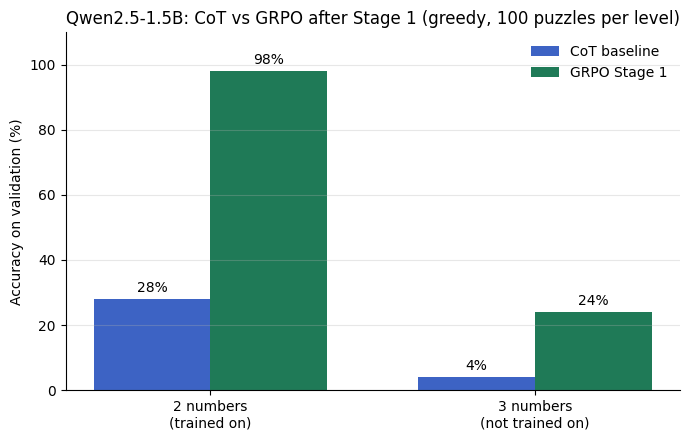

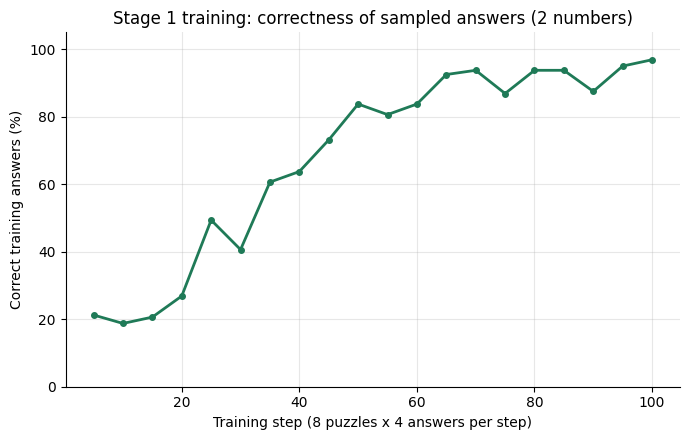

['stage1_val_accuracy.png', 'run_info.json', 'Qwen2.5-1.5B-Instruct_grpo_val_summary.json', 'stage1.log', 'log_history.json', 'Qwen2.5-1.5B-Instruct_cot_val_summary.json', 'stage1_training_curve.png']


In [20]:
# Stage 1 graphs -> saved in results/stage1/
#  (a) validation accuracy: CoT baseline vs GRPO Stage 1, per puzzle size
#  (b) training curve: fraction of correct answers per step (sampled answers, temperature 1.0)
import json, os, shutil
import matplotlib.pyplot as plt

OUT = "results/stage1"
os.makedirs(OUT, exist_ok=True)
COT_COLOR, GRPO_COLOR = "#3D63C4", "#1F7A57"     # same colors family as our baseline charts

# ---------- (a) validation accuracy ----------
cot  = json.load(open("results/Qwen2.5-1.5B-Instruct_cot_val_summary.json"))
grpo = json.load(open("results/Qwen2.5-1.5B-Instruct_grpo_val_summary.json"))
levels = ["2_numbers", "3_numbers"]
labels = ["2 numbers\n(trained on)", "3 numbers\n(not trained on)"]
x = range(len(levels)); w = 0.36

fig, ax = plt.subplots(figsize=(7, 4.5))
b1 = ax.bar([i - w/2 for i in x], [cot[l]["accuracy"] for l in levels],  w, label="CoT baseline", color=COT_COLOR)
b2 = ax.bar([i + w/2 for i in x], [grpo[l]["accuracy"] for l in levels], w, label="GRPO Stage 1", color=GRPO_COLOR)
ax.bar_label(b1, fmt="%.0f%%", padding=3); ax.bar_label(b2, fmt="%.0f%%", padding=3)
ax.set_xticks(list(x)); ax.set_xticklabels(labels)
ax.set_ylabel("Accuracy on validation (%)"); ax.set_ylim(0, 110)
ax.set_title("Qwen2.5-1.5B: CoT vs GRPO after Stage 1 (greedy, 100 puzzles per level)")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{OUT}/stage1_val_accuracy.png", dpi=150); plt.show()

# ---------- (b) training curve ----------
log = [r for r in json.load(open("checkpoints/stage1/log_history.json")) if "reward" in r]
steps   = [r["step"] for r in log]
correct = [100 * r["rewards/correctness_reward/mean"] for r in log]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(steps, correct, color=GRPO_COLOR, linewidth=2, marker="o", markersize=4)
ax.set_xlabel("Training step (8 puzzles x 4 answers per step)")
ax.set_ylabel("Correct training answers (%)"); ax.set_ylim(0, 105)
ax.set_title("Stage 1 training: correctness of sampled answers (2 numbers)")
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT}/stage1_training_curve.png", dpi=150); plt.show()

# ---------- copy the Stage 1 result files next to the graphs ----------
for f in ["checkpoints/stage1/log_history.json", "checkpoints/stage1/run_info.json", "logs/stage1.log",
          "results/Qwen2.5-1.5B-Instruct_cot_val_summary.json",
          "results/Qwen2.5-1.5B-Instruct_grpo_val_summary.json"]:
    shutil.copy(f, OUT)
print(os.listdir(OUT))

In [21]:
# One zip with the results folder + the trained adapter.
!zip -qr /kaggle/working/stage1.zip results/stage1 checkpoints/stage1/final
!ls -lh /kaggle/working/stage1.zip

-rw-r--r-- 1 root root 68M Nov 15 17:53 /kaggle/working/stage1.zip
